In [1]:
from laplacians import *

import dionysus as dio
import numpy as np
import time
import gudhi as gd
import matplotlib.pyplot as plt
import petls
import pandas as pd

Filtration with 239 simplices


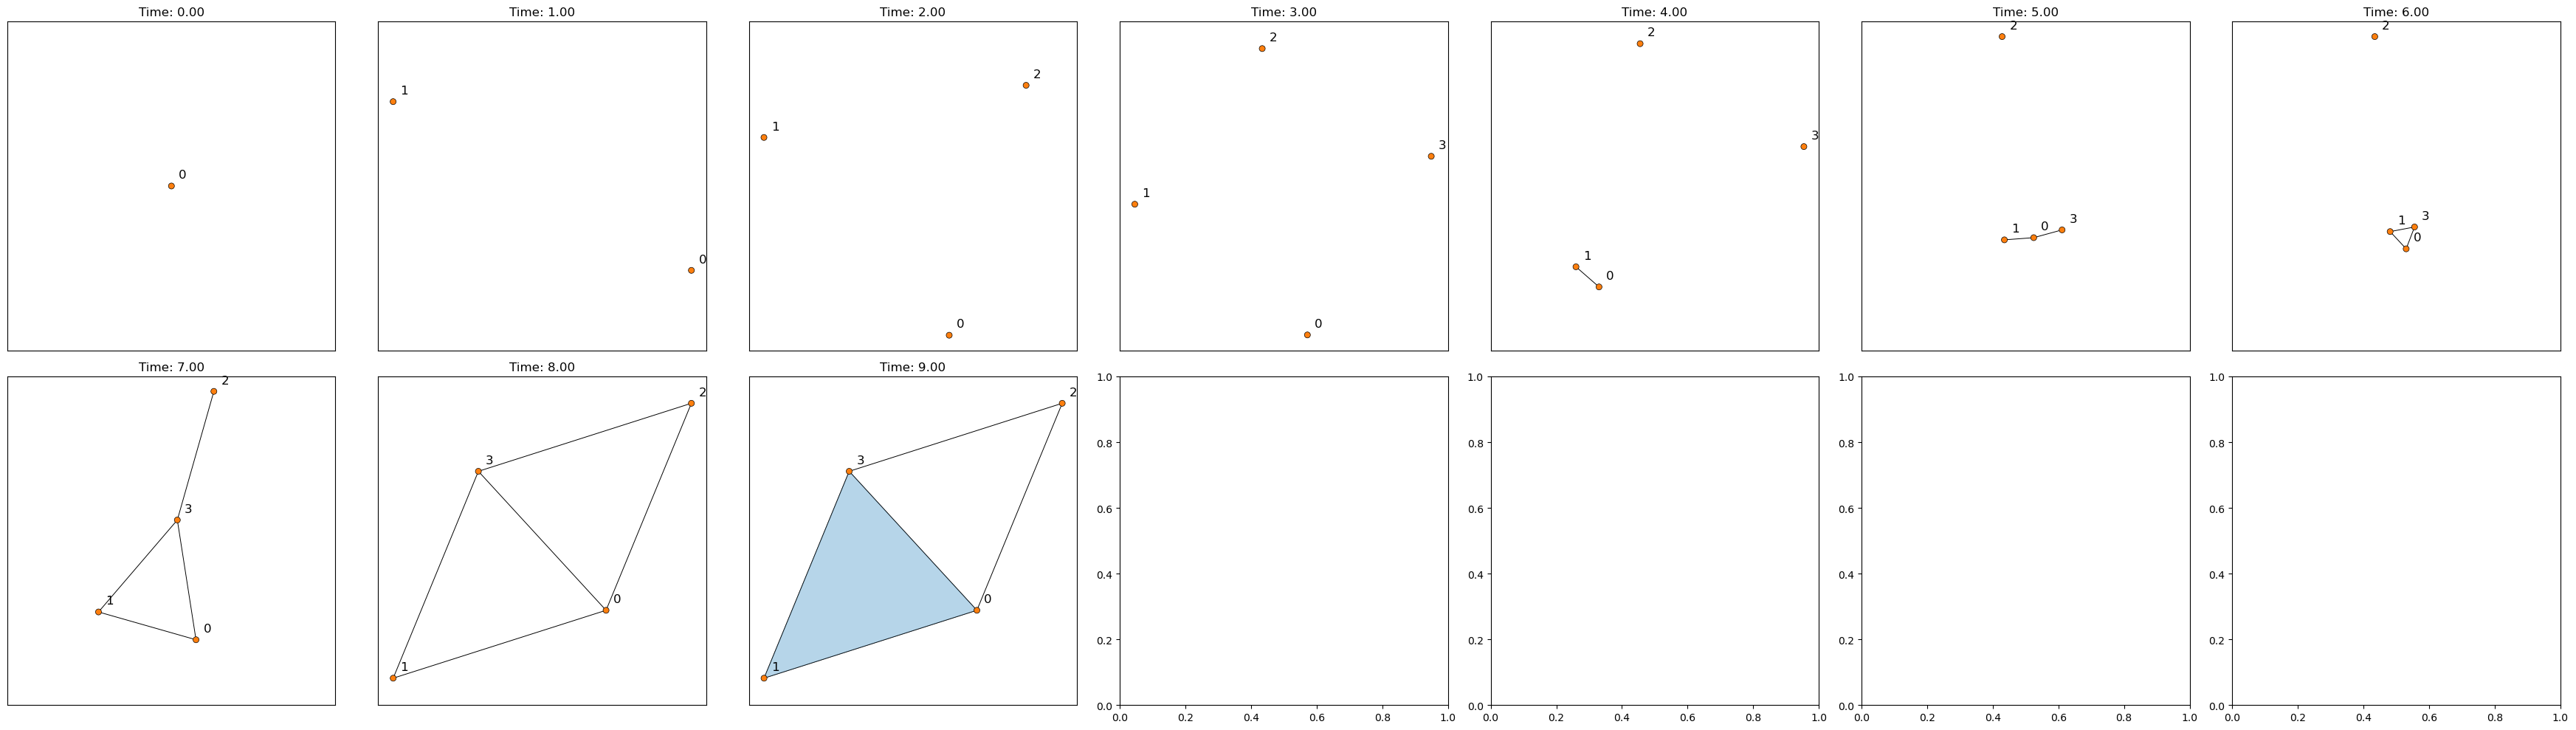

In [2]:
def sample_unit_sphere(n, dim=3, rng=None):
    rng = np.random.default_rng(rng)
    points = rng.standard_normal((n, dim))
    return points / np.linalg.norm(points, axis=1, keepdims=True)

simplices = [([0], 0), ([1], 1), ([2], 2), ([3], 3), ([1,0], 4), ([0,3], 5), ([1,3], 6), ([2,3], 7), ([0,2], 8), ([0,1,3], 9)]#, ([0,2,3], 10)]
# simplices = [([0], 0), ([1], 1), ([2], 2), ([3], 3), ([4], 4), ([0,2], 5), 
#              ([2,4], 6), ([1,4], 7), ([0,1], 8), ([3,4], 9), ([2,3], 10), ([1,2], 11), 
#              ([1,3], 12), ([0,3], 13), ([0,2,3], 14), ([1,3,4], 15), ([0,1,3], 16), ([0,1,2], 17),
#              ([2,3,4], 18), ([1,2,4], 19), ([1,2,3], 20), ([0,1,2,3], 21)]

f = dio.Filtration()
for vertices, t in simplices:
    f.append(dio.Simplex(vertices, t))

n_points = 20
# points_in_circle = np.array([[np.cos(2*np.pi*i/n_points), np.sin(2*np.pi*i/n_points)] for i in range(n_points)])
# f_circle = dio.fill_rips(points_in_circle, 5, np.inf)

points_sphere = sample_unit_sphere(n_points, dim=3, rng=0)

st = gd.AlphaComplex(points=points_sphere).create_simplex_tree()
# st = gd.RipsComplex(points=points_sphere, max_edge_length=np.inf).create_simplex_tree(max_dimension=3)
f_sphere = gudhi_to_dio(st)
# f_sphere = dio.fill_rips(points_sphere, 3, 1.25)
print(f_sphere)

draw_filtration(f, n_per_row=7)

In [3]:
np.random.seed(0)
random_points = np.random.rand(100, 2)
# random_points = np.hstack([random_points, np.zeros((random_points.shape[0], 1))])
st = gd.AlphaComplex(points=random_points).create_simplex_tree()
# st = gd.RipsComplex(points=random_points, max_edge_length=threshold).create_simplex_tree(max_dimension=4)
f_random = gudhi_to_dio(st)
# f_random = dio.fill_rips(random_points, 4, 0.3)
f_random

Filtration with 569 simplices

In [4]:
# chosen_points = random_points
chosen_points = points_sphere

# chosen_f = f_random
chosen_f = f_sphere

threshold = 3

## Combinatorial Laplacian

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0: 0it [00:00, ?it/s]

Computing eigenvalues for q=1: 0it [00:00, ?it/s]

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0: 0it [00:00, ?it/s]

Computing eigenvalues for q=1: 0it [00:00, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:434: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


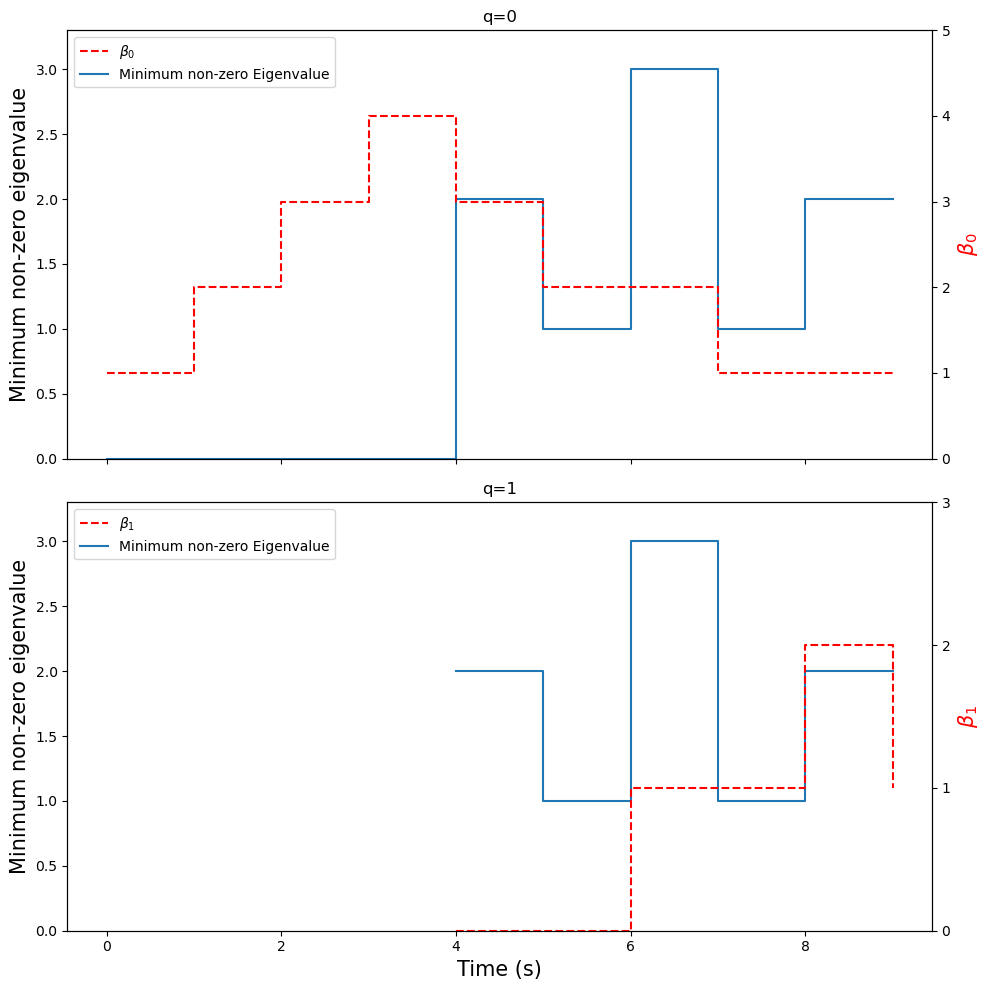

In [5]:
eigenvalues_combi, relevant_times_combi = combinatorial_Laplacian_eigenvalues(f=f)
plot_combinatorial_eigenvalues(eigenvalues_combi, relevant_times_combi, f=f, plot_type_to_fun= {"min": {"function": np.min, "title": "Minimum non-zero Eigenvalue", "use_pos": True}}, labels = [lambda q : fr'Minimum non-zero eigenvalue', lambda q : fr'$\beta_{q}$'])
plt.tight_layout()
plt.savefig("results/figures/example_filtration_combi_lap_min_eval.pdf", bbox_inches='tight', dpi=300)

## Standard PL

Computing boundary matrices:   0%|          | 0/239 [00:00<?, ?it/s]

Computing eigenvalues for q=0:   0%|          | 0/78 [00:00<?, ?it/s]

Computing eigenvalues for q=1:   0%|          | 0/78 [00:00<?, ?it/s]

Computing eigenvalues for q=2:   0%|          | 0/78 [00:00<?, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


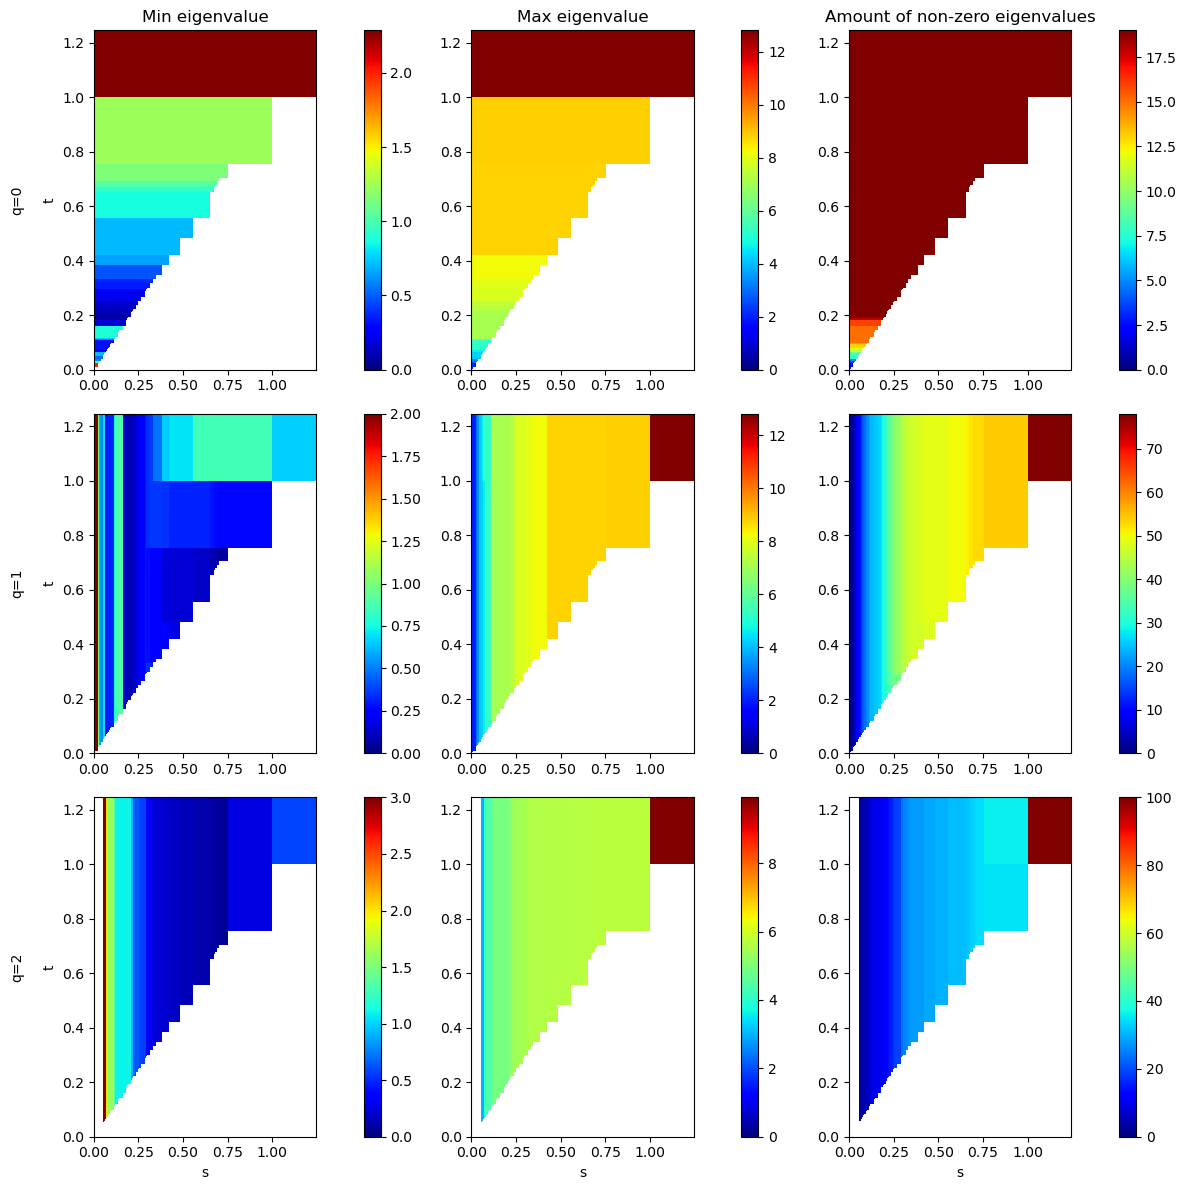

In [6]:
eigenvalues, relevant_times = persistent_Laplacian_eigenvalues(f=chosen_f, up_only=False, max_dim=2)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0})

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=1:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=2:   0%|          | 0/10 [00:00<?, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


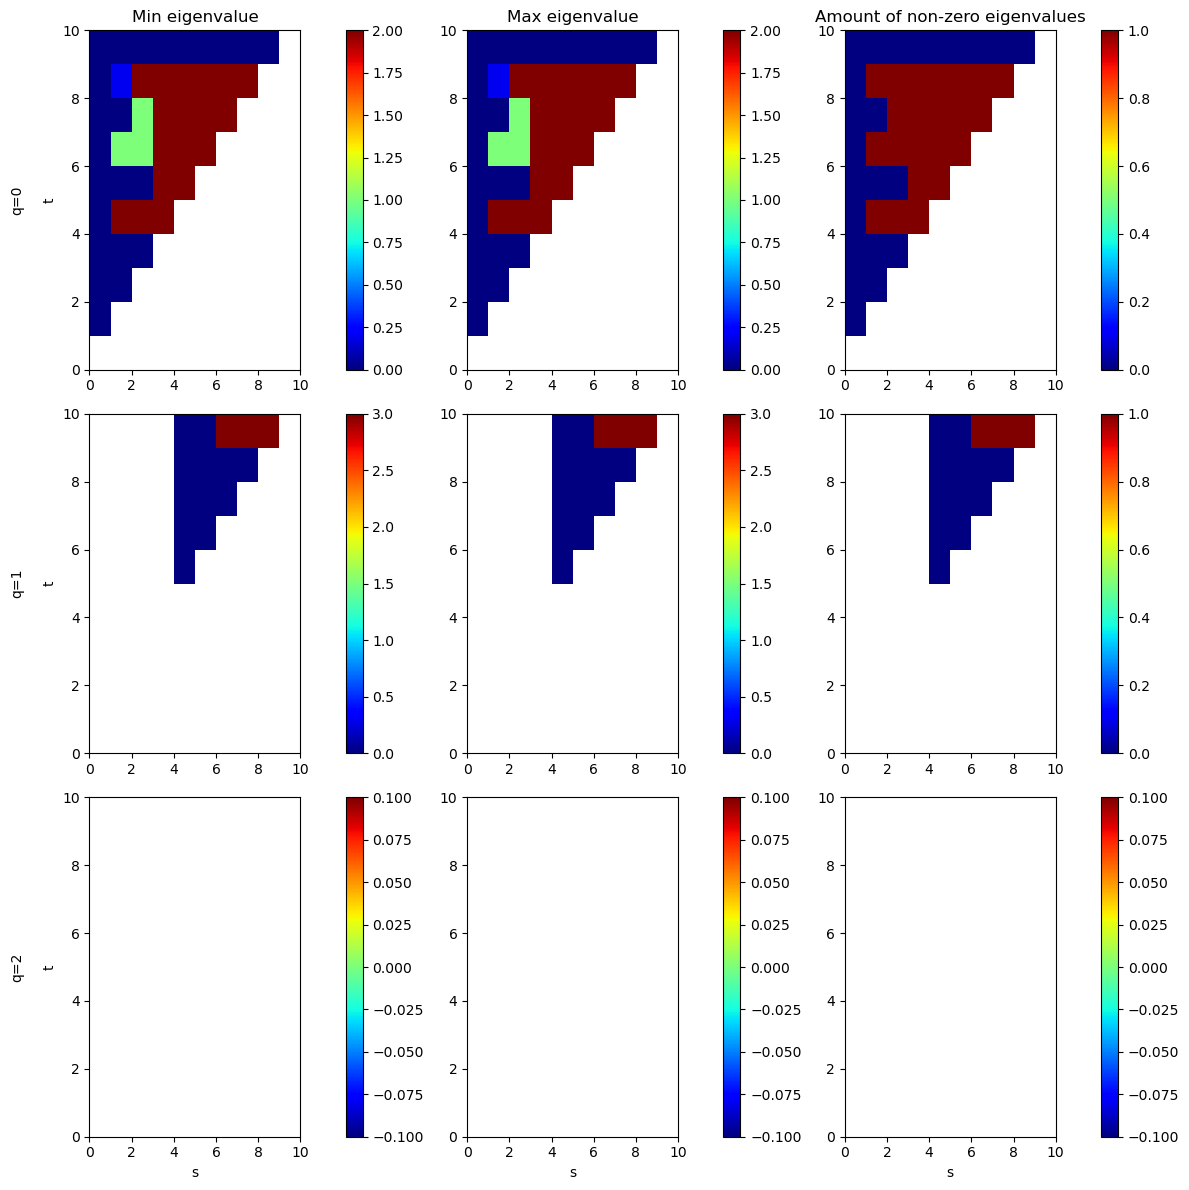

In [7]:
eigenvalues, relevant_times = horizontal_eigenvalues(f=f, up_only=True, max_dim=2)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0})

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=1:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=2:   0%|          | 0/10 [00:00<?, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


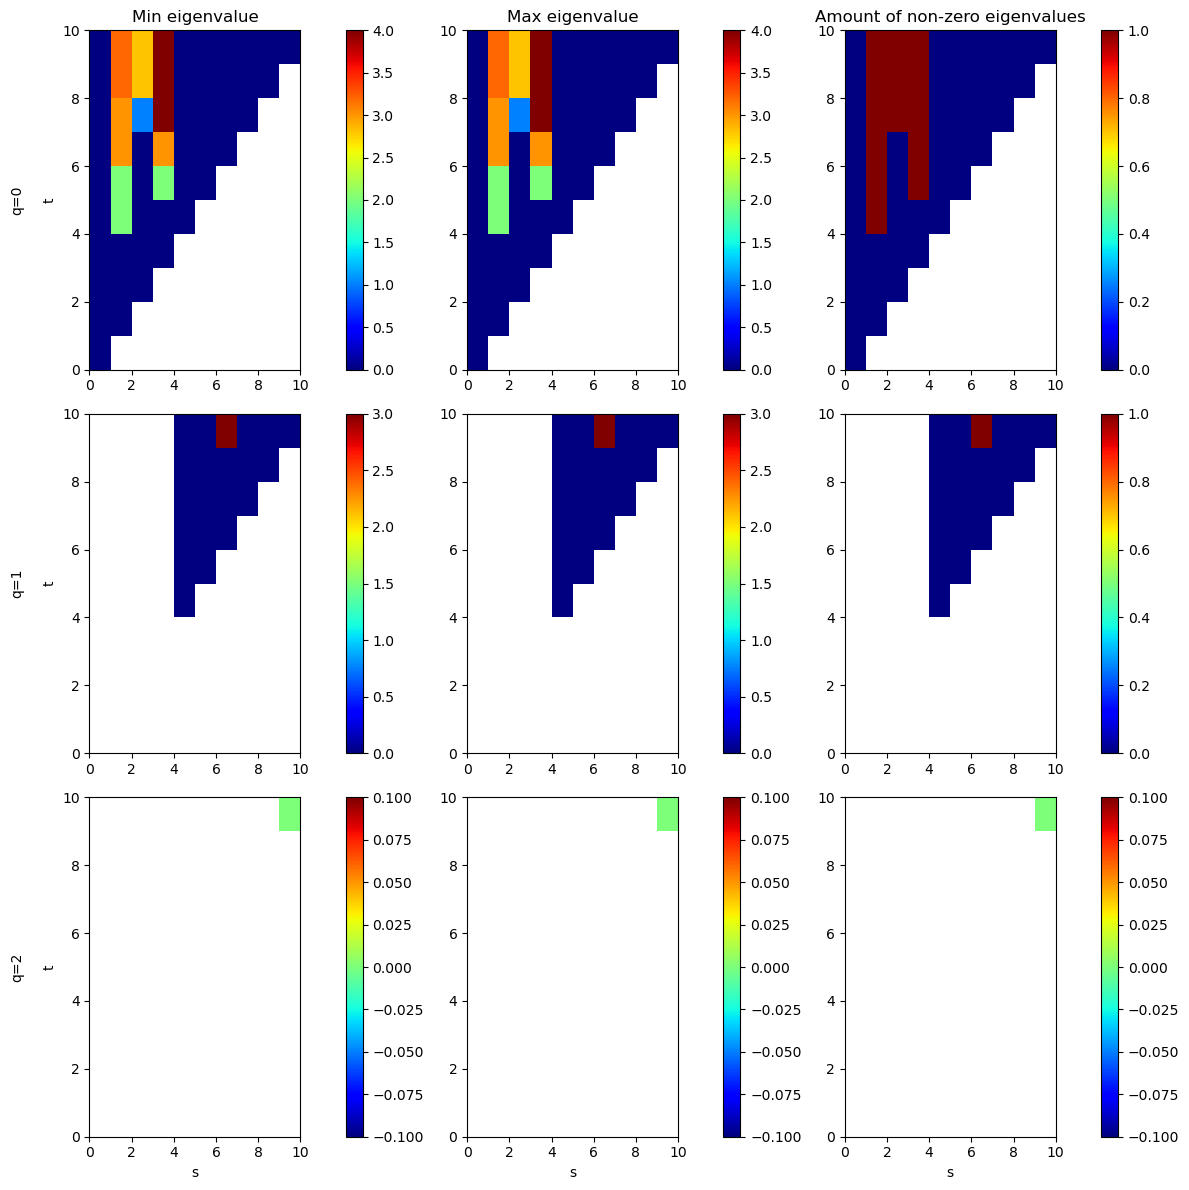

In [8]:
eigenvalues, relevant_times = vertical_eigenvalues(f=f, up_only=True, max_dim=2)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0})

## With new method

Computing boundary matrices:   0%|          | 0/239 [00:00<?, ?it/s]

Standard algorithm:   0%|          | 0/78 [00:00<?, ?it/s]

  0%|          | 0/55 [00:00<?, ?it/s]

Standard algorithm:   0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/136 [00:00<?, ?it/s]

Standard algorithm:   0%|          | 0/41 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Time taken for PL eigenvalues using new persistent chains: 0.25019311904907227


/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


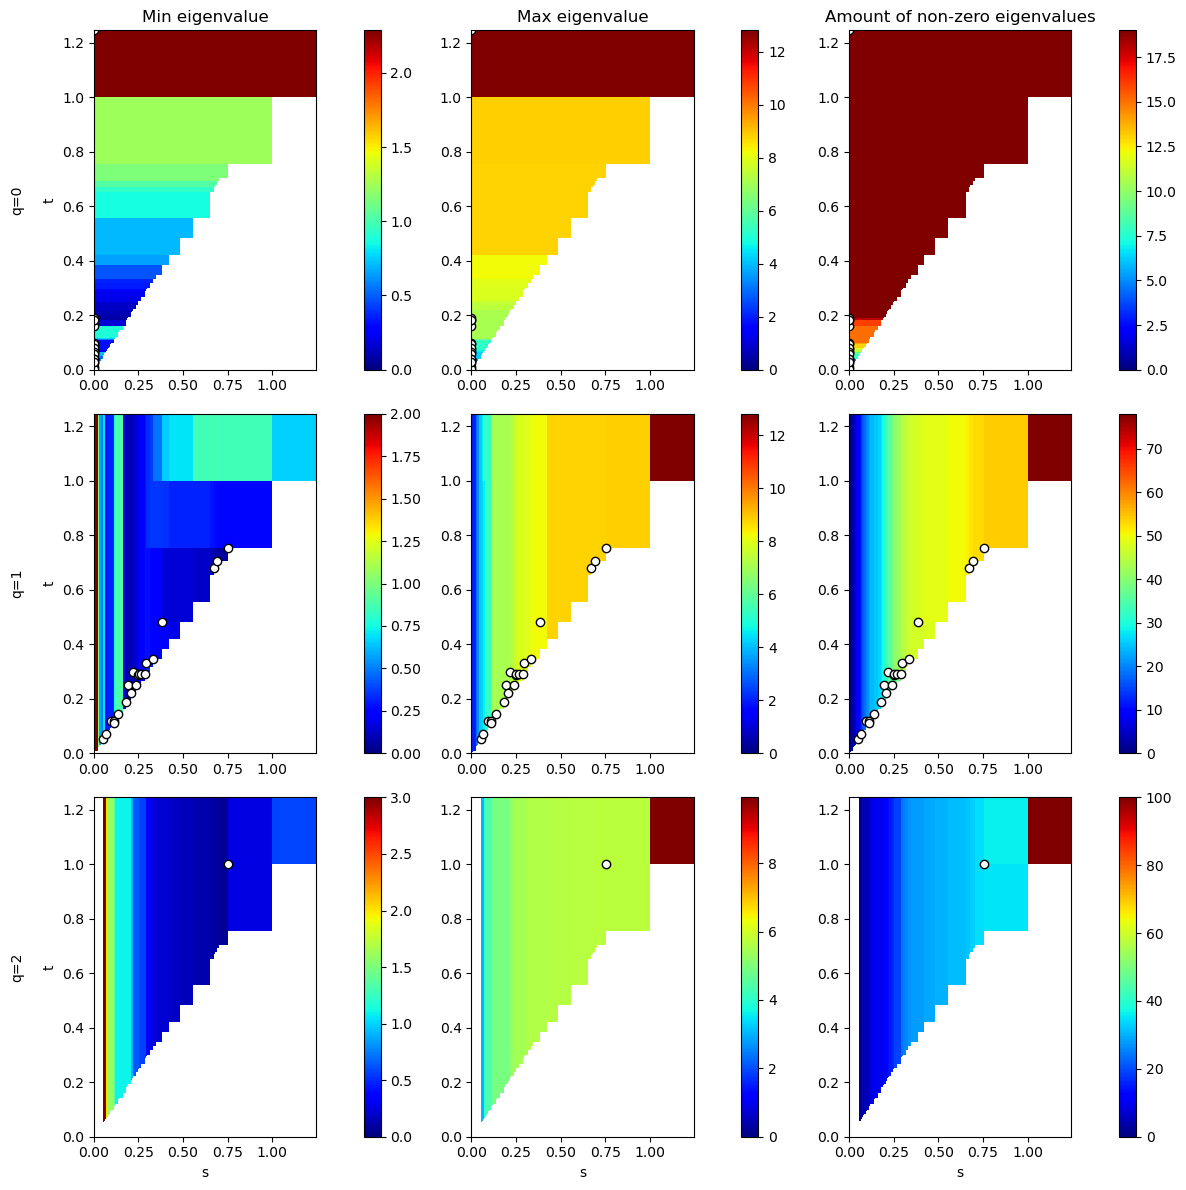

In [9]:
stime = time.time()
# f = dio.fill_rips(random_points, 2, 0.1)
eigenvalues, relevant_times = new_persistent_chains(f=chosen_f, max_dim=2, up_only=False, fill_eigenvalues=True)
print("Time taken for PL eigenvalues using new persistent chains:", time.time() - stime)
_ = plot_eigenvalues(eigenvalues,  f=chosen_f, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], fill_up_figure=False, plot_args_mesh = {"vmin": 0})

## Other libraries

Time taken for PL eigenvalues using petls: 0.4499237537384033


/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


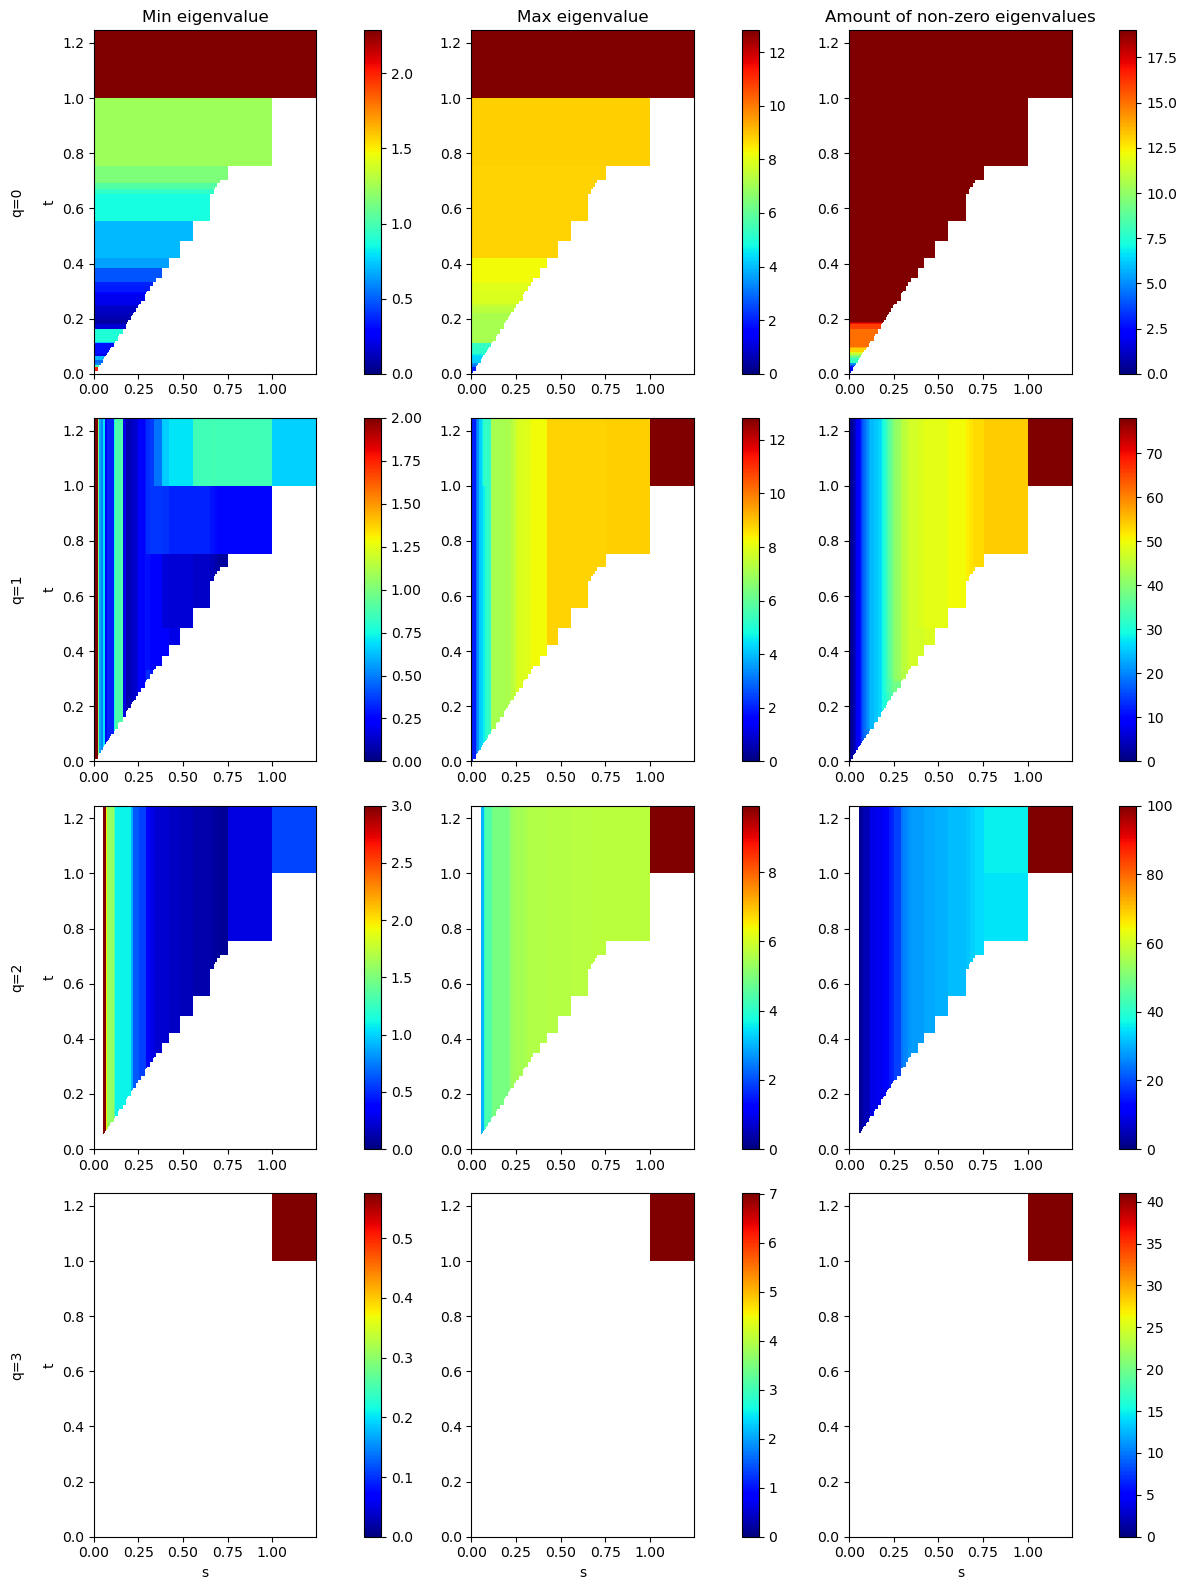

In [10]:
dims = [0, 1, 2, 3]
stime = time.time()
# petls_complex = petls.Rips(points = chosen_points, threshold=threshold)
petls_complex = petls.Alpha(points = chosen_points, max_dim=3)
# petls_complex = petls.Complex(simplex_tree=st)
request_list = petls_complex.filtration_list_to_spectra_request(petls_complex.get_all_filtrations(),dims=dims, allpairs=True)
# spectra = petls.Rips(points = chosen_points, threshold=threshold).spectra(allpairs=True)
spectra = petls_complex.eigenpairs(request_list=request_list)
print("Time taken for PL eigenvalues using petls:", time.time() - stime)
eigenvalues, relevant_times = petls_output_to_eigenvalues(spectra)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0}, tolerance=1e-5)
# plt.close()
# eigenvalues

Computing boundary matrices:   0%|          | 0/239 [00:00<?, ?it/s]

Standard algorithm:   0%|          | 0/78 [00:00<?, ?it/s]

Standard algorithm:   0%|          | 0/100 [00:00<?, ?it/s]

Standard algorithm:   0%|          | 0/41 [00:00<?, ?it/s]

Time taken for PL eigenvalues using petls combined: 0.1950685977935791


/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


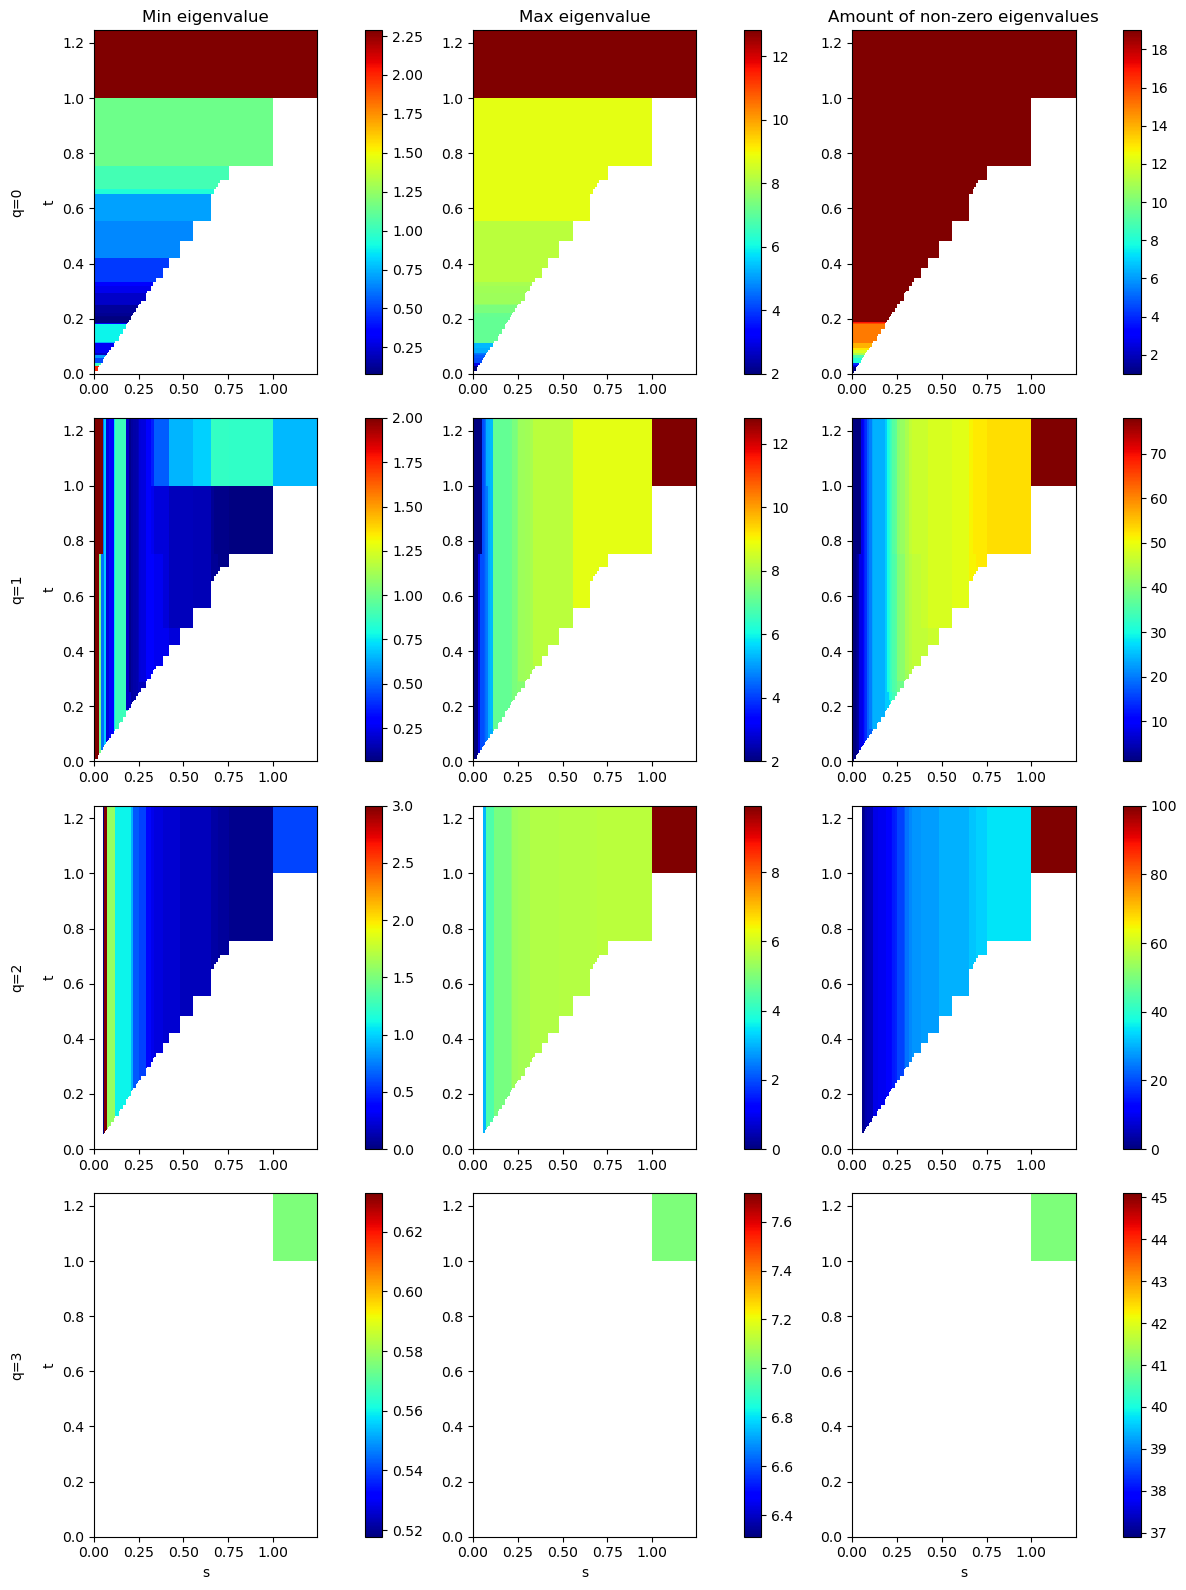

In [11]:
stime = time.time()
eigenvalues, relevant_times = petls_combined(points = chosen_points, threshold=threshold, max_dim=3, fill_eigenvalues=True, round_to=None, filtration_type="alpha")
print("Time taken for PL eigenvalues using petls combined:", time.time() - stime)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], fill_up_figure=False)